# Tema 13 · Modelos de Clasificación — Guía 3: Random Forest, Gradient Boosting, XGBoost y LightGBM en Bolsa
**Curso:** Minería de Datos en Python (DM) · FISI · UNMSM · 2026-II · **Laboratorio 12 · Guía 3** · Docente: Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Objetivo:** distinguir **bagging** (Random Forest: muchos árboles independientes, se promedian) de **boosting** (Gradient Boosting, XGBoost, LightGBM: árboles en secuencia, cada uno corrige al anterior), leer **curvas de validación**, usar **early stopping** y **permutación de importancias**.

**Datos:** Yahoo Finance (28 activos, hasta el 19-nov-2026) con respaldo en CSV. **Nada de este material es asesoría de inversión.**

# 1. Importación de librerías y carga de datos

In [1]:
# Librerías del laboratorio
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")
SEMILLA = 2026  # semilla global: reproducibilidad
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"}
)

In [2]:
# Librerías de esta guía
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit,
    train_test_split,
    validation_curve,
)
from sklearn.inspection import permutation_importance

In [3]:
# Precios ajustados de 28 activos hasta el cierre del 19-nov-2026. Si los 4 CSV del curso (carpeta D03) están junto al notebook se usan
# (las cifras coinciden con las de la guía); si no, se descargan de Yahoo Finance (pueden variar en centésimas si Yahoo revisó precios)
import os

TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = {
    "cierres": "26.11.20.cierres_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "altos": "26.11.20.altos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "bajos": "26.11.20.bajos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "volumenes": "26.11.20.volumenes_28_activos_2010-01-04_2026-11-19.csv",
}
if all(os.path.exists(f) for f in ARCH.values()):
    cierres, altos, bajos, volumenes = [
        pd.read_csv(ARCH[k], index_col=0, parse_dates=True)
        for k in ["cierres", "altos", "bajos", "volumenes"]
    ]
    print("Se usó la foto de datos del curso (CSV)")
else:
    try:
        d = yf.download(
            TICKERS,
            start="2010-01-01",
            end="2026-11-20",
            auto_adjust=True,
            progress=False,
        )
        cierres, altos, bajos, volumenes = [
            d[c].reindex(columns=TICKERS) for c in ["Close", "High", "Low", "Volume"]
        ]
        print("Se descargó de Yahoo Finance")
    except Exception as e:
        raise SystemExit(
            "Falló la descarga de Yahoo Finance (%s): suba los 4 CSV del curso junto "
            "al notebook"
            % e
        )
for t in (cierres, altos, bajos, volumenes):
    t.index = pd.to_datetime(t.index)
print(
    "Dimensiones:",
    cierres.shape,
    "| desde",
    cierres.index.min().date(),
    "hasta",
    cierres.index.max().date(),
)
print(
    "Último cierre de SPY:",
    round(float(cierres["SPY"].dropna().iloc[-1]), 2),
    "| VIX:",
    round(float(cierres["^VIX"].dropna().iloc[-1]), 2),
)

Se usó la foto de datos del curso (CSV)
Dimensiones: (4249, 28) | desde 2010-01-04 hasta 2026-11-19
Último cierre de SPY: 715.87 | VIX: 28.44


# 2. Parte I — Laboratorio de contraste sintético (Mundo 2)
**Fenómeno F4 (donde funcionan).** Con una **interacción** (el evento ocurre cuando dos variables tienen el mismo signo, como un XOR), un modelo lineal no sirve (AUC ≈ 0,5) y los árboles sí.

In [4]:
# Interacción tipo XOR: la logística no puede, los ensambles sí
n = 4000
Xi = rng.normal(0, 1, (n, 6))
yi = ((Xi[:, 0] * Xi[:, 1]) > 0).astype(
    int
)  # solo importa el producto de las dos primeras variables
Xi_e, Xi_p, yi_e, yi_p = train_test_split(
    Xi, yi, test_size=0.4, random_state=SEMILLA, stratify=yi
)
cand = {
    "Logística": LogisticRegression(max_iter=2000),
    "Árbol (profundidad 4)": DecisionTreeClassifier(max_depth=4, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=SEMILLA, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEMILLA),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.1, random_state=SEMILLA, n_jobs=1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300,
        num_leaves=8,
        learning_rate=0.1,
        random_state=SEMILLA,
        verbose=-1,
    ),
}
filas = []
for nombre, m in cand.items():
    p = m.fit(Xi_e, yi_e).predict_proba(Xi_p)[:, 1]
    filas.append(
        [nombre, roc_auc_score(yi_p, p), accuracy_score(yi_p, (p >= 0.5).astype(int))]
    )
xor = pd.DataFrame(filas, columns=["modelo", "AUC-ROC", "exactitud"])
print(xor.round(3).to_string(index=False))

               modelo  AUC-ROC  exactitud
            Logística     0.49      0.494
Árbol (profundidad 4)     1.00      1.000
        Random Forest     1.00      0.999
    Gradient Boosting     1.00      1.000
              XGBoost     1.00      0.999
             LightGBM     1.00      1.000


**Fenómeno F4 (donde fallan).** Con **pocos datos y mucho ruido**, un ensamble flexible memoriza el ruido: el AUC de entrenamiento sube a 1 y el de validación se queda en el azar. La **curva de validación** lo muestra al variar la profundidad.

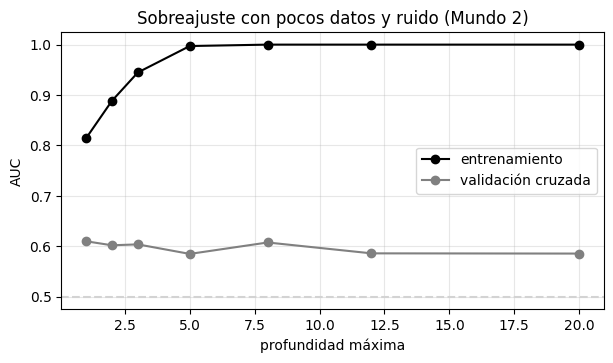

AUC de entrenamiento con profundidad 20: 1.0 | AUC de validación: 0.585


In [5]:
# Curva de validación: profundidad máxima del Random Forest con 300 filas y 20 variables de puro ruido salvo una débil
ns = 300
Xr = rng.normal(0, 1, (ns, 20))
yr = (Xr[:, 0] * 0.4 + rng.normal(0, 1, ns) > 0).astype(int)
profs = [1, 2, 3, 5, 8, 12, 20]
ent_sc, val_sc = validation_curve(
    RandomForestClassifier(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
    Xr,
    yr,
    param_name="max_depth",
    param_range=profs,
    cv=5,
    scoring="roc_auc",
)
plt.figure(figsize=(7, 3.6))
plt.plot(profs, ent_sc.mean(axis=1), "o-", color="black", label="entrenamiento")
plt.plot(profs, val_sc.mean(axis=1), "o-", color="gray", label="validación cruzada")
plt.axhline(0.5, ls="--", color="lightgray")
plt.xlabel("profundidad máxima")
plt.ylabel("AUC")
plt.legend()
plt.title("Sobreajuste con pocos datos y ruido (Mundo 2)")
plt.show()
print(
    "AUC de entrenamiento con profundidad 20:",
    round(ent_sc.mean(axis=1)[-1], 3),
    "| AUC de validación:",
    round(val_sc.mean(axis=1)[-1], 3),
)

# 3. Datos de SPY: variables causales y objetivos
Partición cronológica 70 % / 30 % con embargo de 22 filas.

In [6]:
# Variables causales de un activo: solo información conocida al cierre del día t
TICKER = "SPY"
cierre = cierres[TICKER].dropna()
alto, bajo, volumen = (
    altos[TICKER].reindex(cierre.index),
    bajos[TICKER].reindex(cierre.index),
    volumenes[TICKER].reindex(cierre.index),
)
vix = cierres["^VIX"].reindex(cierre.index).ffill()
r = np.log(cierre).diff() * 100  # retorno logarítmico diario en %
X = pd.DataFrame(
    {
        "ret_1": r,
        "ret_5": r.rolling(5).sum(),
        "ret_22": r.rolling(22).sum(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(5),
        "parkinson": (np.log(alto / bajo) / np.sqrt(4 * np.log(2)) * 100)
        .rolling(5)
        .mean(),
        "dist_sma50": (cierre / cierre.rolling(50).mean() - 1) * 100,
        "rango_22": (cierre - bajo.rolling(22).min())
        / (alto.rolling(22).max() - bajo.rolling(22).min()),
        "d_volumen": np.log(volumen / volumen.rolling(22).mean()),
    }
).loc["2012-01-01":]
VARS = list(X.columns)
print(TICKER, "| variables:", VARS)

SPY | variables: ['ret_1', 'ret_5', 'ret_22', 'vol_5', 'vol_22', 'vol_66', 'vix', 'd_vix', 'parkinson', 'dist_sma50', 'rango_22', 'd_volumen']


In [7]:
# Tres objetivos binarios del mismo activo (todos miran al FUTURO; las variables solo al pasado)
y_dir5 = (cierre.shift(-5) / cierre > 1).astype(
    float
)  # ¿cierra más alto dentro de 5 sesiones?
vol_fut = r.shift(-22).rolling(22).std()  # volatilidad de las próximas 22 sesiones
caida = pd.concat([cierre.shift(-k) / cierre - 1 for k in range(1, 11)], axis=1).min(
    axis=1
)  # peor caída en las próximas 10 sesiones
datos = (
    X.join(y_dir5.rename("dir5"))
    .join(vol_fut.rename("vol_fut"))
    .join(caida.rename("caida"))
    .dropna()
)
corte = int(len(datos) * 0.7)
H = 22  # embargo = horizonte más largo
ent, pru = datos.iloc[: corte - H], datos.iloc[corte:]
umbral_vol = ent["vol_fut"].quantile(0.70)  # el umbral sale SOLO del entrenamiento
for t in (ent, pru):
    t["alta_vol"] = (t["vol_fut"] > umbral_vol).astype(int)
    t["crash"] = (t["caida"] <= -0.04).astype(int)
    t["dir5"] = t["dir5"].astype(int)
print(
    "Entrenamiento:",
    len(ent),
    "filas, hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "filas, desde",
    pru.index.min().date(),
)
for obj in ["dir5", "alta_vol", "crash"]:
    print(
        f"{obj:9s} tasa base entrenamiento {ent[obj].mean():.3f} | prueba "
        f"{pru[obj].mean():.3f}"
    )

Entrenamiento: 2582 filas, hasta 2022-04-05 | Prueba: 1117 filas, desde 2022-05-09
dir5      tasa base entrenamiento 0.624 | prueba 0.601
alta_vol  tasa base entrenamiento 0.300 | prueba 0.353
crash     tasa base entrenamiento 0.088 | prueba 0.103


# 4. Parte II — Competencia de ensambles para el régimen de alta volatilidad (Mundo 3)
Cada modelo se afina con `RandomizedSearchCV` y `TimeSeriesSplit(gap=22)` **solo en el entrenamiento**; la prueba se mira una vez.

In [8]:
# Búsqueda aleatoria con validación cronológica (gap = 22)
tscv = TimeSeriesSplit(n_splits=4, gap=H)
espacios = {
    "Logística": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        {"logisticregression__C": np.logspace(-3, 1, 20)},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEMILLA, n_jobs=-1),
        {
            "n_estimators": [200, 400],
            "max_depth": [3, 5, 8],
            "min_samples_leaf": [10, 30, 60],
            "max_features": [0.3, 0.6],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=SEMILLA),
        {
            "n_estimators": [100, 200],
            "learning_rate": [0.03, 0.1],
            "max_depth": [2, 3],
            "subsample": [0.6, 0.8],
        },
    ),
    "XGBoost": (
        XGBClassifier(random_state=SEMILLA, n_jobs=1),
        {
            "n_estimators": [150, 300],
            "learning_rate": [0.03, 0.1],
            "max_depth": [2, 3, 4],
            "subsample": [0.6, 0.8],
            "min_child_weight": [5, 20],
        },
    ),
    "LightGBM": (
        LGBMClassifier(random_state=SEMILLA, verbose=-1),
        {
            "n_estimators": [150, 300],
            "learning_rate": [0.03, 0.1],
            "num_leaves": [4, 8, 16],
            "min_child_samples": [20, 50],
            "subsample": [0.8],
            "subsample_freq": [1],
        },
    ),
}
mejores, filas = {}, []
for nombre, (m, rej) in espacios.items():
    bus = RandomizedSearchCV(
        m, rej, n_iter=8, cv=tscv, scoring="roc_auc", random_state=SEMILLA, n_jobs=1
    ).fit(ent[VARS], ent["alta_vol"])
    mejores[nombre] = bus.best_estimator_
    p_e, p = bus.predict_proba(ent[VARS])[:, 1], bus.predict_proba(pru[VARS])[:, 1]
    filas.append(
        [
            nombre,
            bus.best_score_,
            roc_auc_score(ent["alta_vol"], p_e),
            roc_auc_score(pru["alta_vol"], p),
            average_precision_score(pru["alta_vol"], p),
            f1_score(pru["alta_vol"], (p >= 0.5).astype(int)),
            brier_score_loss(pru["alta_vol"], p),
        ]
    )
comp = pd.DataFrame(
    filas,
    columns=[
        "modelo",
        "AUC_validación",
        "AUC_entrenamiento",
        "AUC_prueba",
        "AUC-PR_prueba",
        "F1_prueba",
        "Brier_prueba",
    ],
).sort_values("AUC_prueba", ascending=False)
print("Tasa base de «alta volatilidad» en la prueba:", round(pru["alta_vol"].mean(), 3))
print(comp.round(3).to_string(index=False))

Tasa base de «alta volatilidad» en la prueba: 0.353
           modelo  AUC_validación  AUC_entrenamiento  AUC_prueba  AUC-PR_prueba  F1_prueba  Brier_prueba
Gradient Boosting           0.662              0.855       0.840          0.785      0.652         0.149
    Random Forest           0.698              0.845       0.834          0.800      0.688         0.141
        Logística           0.680              0.798       0.831          0.792      0.657         0.148
          XGBoost           0.669              0.930       0.823          0.755      0.647         0.155
         LightGBM           0.681              0.934       0.729          0.653      0.508         0.191


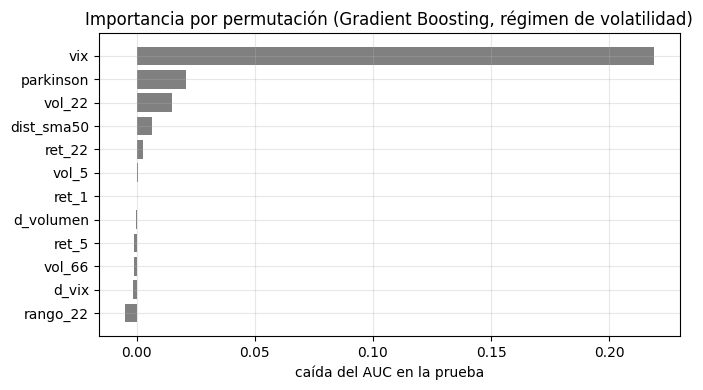

Mejor modelo: Gradient Boosting
vix           0.2188
parkinson     0.0210
vol_22        0.0148
dist_sma50    0.0063
ret_22        0.0025
vol_5         0.0004


In [9]:
# Importancia por permutación en la prueba (caída del AUC al barajar cada variable) del mejor modelo
mejor = comp.iloc[0]["modelo"]
perm = permutation_importance(
    mejores[mejor],
    pru[VARS],
    pru["alta_vol"],
    n_repeats=20,
    random_state=SEMILLA,
    scoring="roc_auc",
)
imp = pd.Series(perm.importances_mean, index=VARS).sort_values()
plt.figure(figsize=(7, 4))
plt.barh(imp.index, imp.values, color="gray")
plt.title(f"Importancia por permutación ({mejor}, régimen de volatilidad)")
plt.xlabel("caída del AUC en la prueba")
plt.tight_layout()
plt.show()
print("Mejor modelo:", mejor)
print(imp.sort_values(ascending=False).round(4).head(6).to_string())

Árboles usados: 22 de 1000 | AUC de validación: 0.774 | AUC de prueba: 0.809


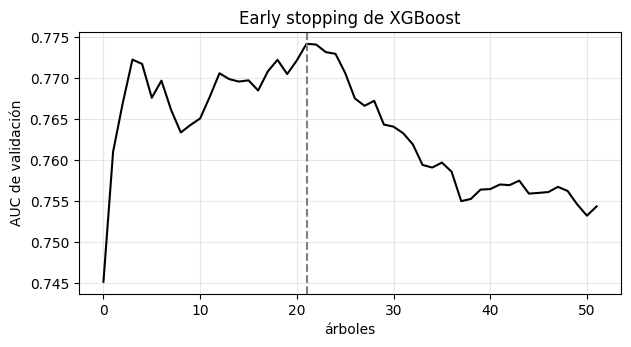

In [10]:
# Early stopping de XGBoost: el número de árboles se elige con una validación cronológica (no con la prueba)
corte_v = int(len(ent) * 0.8)
ent2, val = ent.iloc[: corte_v - H], ent.iloc[corte_v:]
xgb_es = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    min_child_weight=10,
    random_state=SEMILLA,
    n_jobs=1,
    early_stopping_rounds=30,
    eval_metric="auc",
)
xgb_es.fit(
    ent2[VARS], ent2["alta_vol"], eval_set=[(val[VARS], val["alta_vol"])], verbose=False
)
hist = xgb_es.evals_result()["validation_0"]["auc"]
print(
    "Árboles usados:",
    xgb_es.best_iteration + 1,
    "de 1000 | AUC de validación:",
    round(max(hist), 3),
    "| AUC de prueba:",
    round(roc_auc_score(pru["alta_vol"], xgb_es.predict_proba(pru[VARS])[:, 1]), 3),
)
plt.figure(figsize=(7, 3.4))
plt.plot(hist, color="black")
plt.axvline(xgb_es.best_iteration, ls="--", color="gray")
plt.xlabel("árboles")
plt.ylabel("AUC de validación")
plt.title("Early stopping de XGBoost")
plt.show()

# 5. Parte III — La dirección a 5 sesiones (Mundo 1): los ensambles memorizan el ruido
El mismo procedimiento sobre `dir5`: el AUC de entrenamiento sube y el de prueba se queda cerca de 0,5.

Tasa base de «sube» en la prueba: 0.601
           modelo  AUC_validación  AUC_entrenamiento  AUC_prueba  exactitud_prueba
        Logística           0.528              0.540       0.498             0.601
    Random Forest           0.562              0.921       0.507             0.588
Gradient Boosting           0.576              0.962       0.524             0.563
          XGBoost           0.556              0.861       0.512             0.568
         LightGBM           0.559              0.909       0.510             0.566


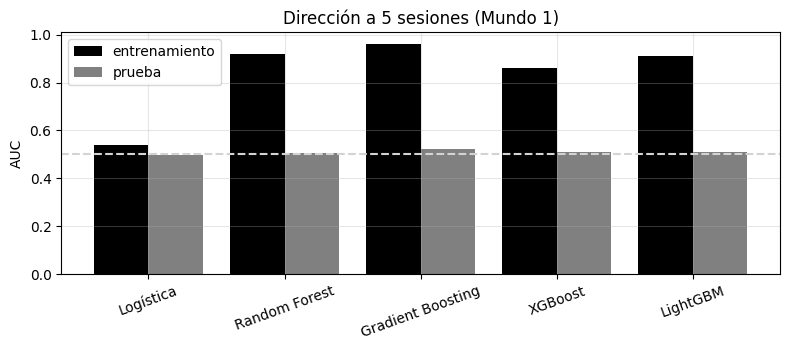

In [11]:
# Mismos cinco modelos sobre la dirección a 5 sesiones
filas = []
for nombre, (m, rej) in espacios.items():
    bus = RandomizedSearchCV(
        m, rej, n_iter=8, cv=tscv, scoring="roc_auc", random_state=SEMILLA, n_jobs=1
    ).fit(ent[VARS], ent["dir5"])
    p_e, p = bus.predict_proba(ent[VARS])[:, 1], bus.predict_proba(pru[VARS])[:, 1]
    filas.append(
        [
            nombre,
            bus.best_score_,
            roc_auc_score(ent["dir5"], p_e),
            roc_auc_score(pru["dir5"], p),
            accuracy_score(pru["dir5"], (p >= 0.5).astype(int)),
        ]
    )
dirm = pd.DataFrame(
    filas,
    columns=[
        "modelo",
        "AUC_validación",
        "AUC_entrenamiento",
        "AUC_prueba",
        "exactitud_prueba",
    ],
)
print("Tasa base de «sube» en la prueba:", round(pru["dir5"].mean(), 3))
print(dirm.round(3).to_string(index=False))
x = np.arange(len(dirm))
plt.figure(figsize=(8, 3.6))
plt.bar(x - 0.2, dirm["AUC_entrenamiento"], 0.4, color="black", label="entrenamiento")
plt.bar(x + 0.2, dirm["AUC_prueba"], 0.4, color="gray", label="prueba")
plt.axhline(0.5, ls="--", color="lightgray")
plt.xticks(x, dirm["modelo"], rotation=20)
plt.ylabel("AUC")
plt.legend()
plt.title("Dirección a 5 sesiones (Mundo 1)")
plt.tight_layout()
plt.show()

# 6. Resumen
- **Bagging** (Random Forest) reduce la varianza promediando árboles; **boosting** reduce el sesgo corrigiendo errores en secuencia.
- Los ensambles ganan cuando hay **interacciones** y datos suficientes (Mundo 2/3); fallan con **pocos datos y ruido**: entrenamiento 1,0, validación 0,5.
- **Early stopping** y la **validación cronológica con embargo** fijan la complejidad sin mirar la prueba.